# 05 · Aprendizaje No Supervisado — Segmentación musical

**Pregunta de negocio:** ¿qué tipos de canciones existen según su *sonido*, independientemente de la etiqueta de género? ¿Hay segmentos con más potencial de popularidad?

- **Datos:** `spotify_clustering_input` — 76.439 canciones × 10 features de audio escaladas (StandardScaler)
- **No se usan** género ni popularidad para agrupar: se usan **después** para interpretar los segmentos
- **Pipeline Kedro:** `unsupervised`

### Técnicas

| Técnica | Uso | Justificación |
|---|---|---|
| **K-Means** | Modelo principal de segmentación | Features continuas y escaladas (la distancia euclídea tiene sentido), escala bien a 76k canciones y sus centroides son interpretables como "perfil promedio" |
| **PCA** | Visualización en 2D | Reduce 10 dimensiones a 2 para ver los clusters |
| **DBSCAN** | Contraste | Agrupa por densidad sin fijar k: verifica si existen grupos naturales bien separados |

In [1]:
%load_ext kedro.ipython

The kedro.ipython extension is already loaded. To reload it, use:
  %reload_ext kedro.ipython


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 90
pd.set_option("display.max_colwidth", 120)

PLOTS = "../results/plots"
params = catalog.load("parameters")

                    INFO     Loading data from parameters (MemoryDataset)...                   ]8;id=12544681;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=12544682;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

In [3]:
X = catalog.load("spotify_clustering_input")
features = catalog.load("spotify_features")
labels = catalog.load("cluster_labels")
print(f"Input clustering: {X.shape}")
X.describe().T[["mean", "std"]].round(2)

                    INFO     Loading data from spotify_clustering_input (CSVDataset)...        ]8;id=12544687;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=12544688;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

                    INFO     Loading data from spotify_features (CSVDataset)...                ]8;id=12544693;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=12544694;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

[10/19/26 23:04:31] INFO     Loading data from cluster_labels (CSVDataset)...                  ]8;id=12544699;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=12544700;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

Input clustering: (76439, 10)


,mean,std
danceability,-0.0,1.0
energy,-0.0,1.0
loudness,-0.0,1.0
speechiness,-0.0,1.0
acousticness,0.0,1.0
instrumentalness,0.0,1.0
liveness,0.0,1.0
valence,0.0,1.0
tempo,0.0,1.0
duration_min,0.0,1.0


## 1. Selección del número de clusters (k)

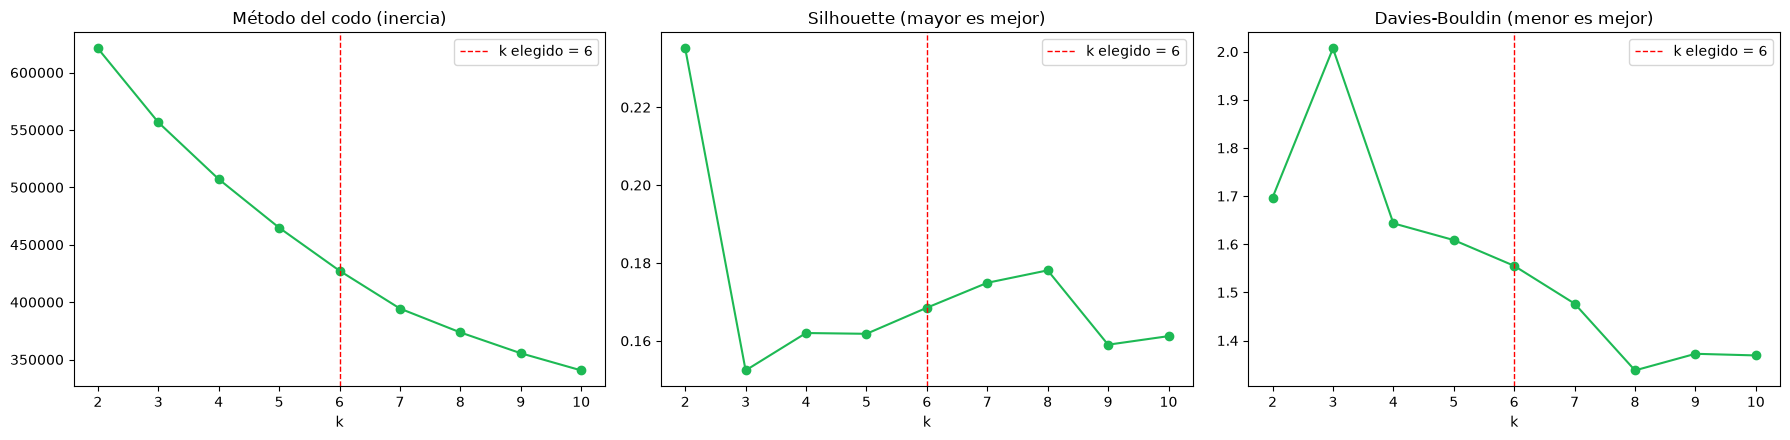

                    INFO     Loading data from kmeans_selection_results (CSVDataset)...        ]8;id=12544705;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=12544706;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,k,inercia,silhouette,davies_bouldin
0,2,620992.7696,0.2351,1.6969
1,3,556630.8090,0.1524,2.0067
2,4,507123.2096,0.1620,1.6434
3,5,464843.1530,0.1618,1.6086
4,6,427356.8342,0.1685,1.5551
5,7,394407.8574,0.1749,1.4766
6,8,373618.4825,0.1781,1.3379
7,9,355488.9002,0.1590,1.3724
8,10,340539.2485,0.1612,1.3690


In [4]:
display(Image(f"{PLOTS}/05_kmeans_selection.png"))
catalog.load("kmeans_selection_results")

Los criterios no coinciden en un único k, algo habitual con datos reales:

- **Codo:** la inercia baja de forma suave, sin un codo marcado.
- **Silhouette:** máximo en k=2, pero solo separa "canciones enérgicas" de "acústicas": demasiado grueso para el negocio.
- Entre k=3 y k=8, **k=6 mejora a k=4 y k=5** en silhouette (0.169) y Davies-Bouldin (1.56).
- Con k=8 aparece un cluster de solo 36 canciones (pistas de más de 50 minutos): segmenta outliers, no tipos de música.

**Se elige k = 6**: buen equilibrio entre métricas y segmentos interpretables y accionables.

Los valores de silhouette (~0.17) indican que los segmentos **se solapan**: la música es un continuo, no grupos perfectamente separados. Aun así, como se ve abajo, los perfiles son claramente distintos.

## 2. Visualización con PCA

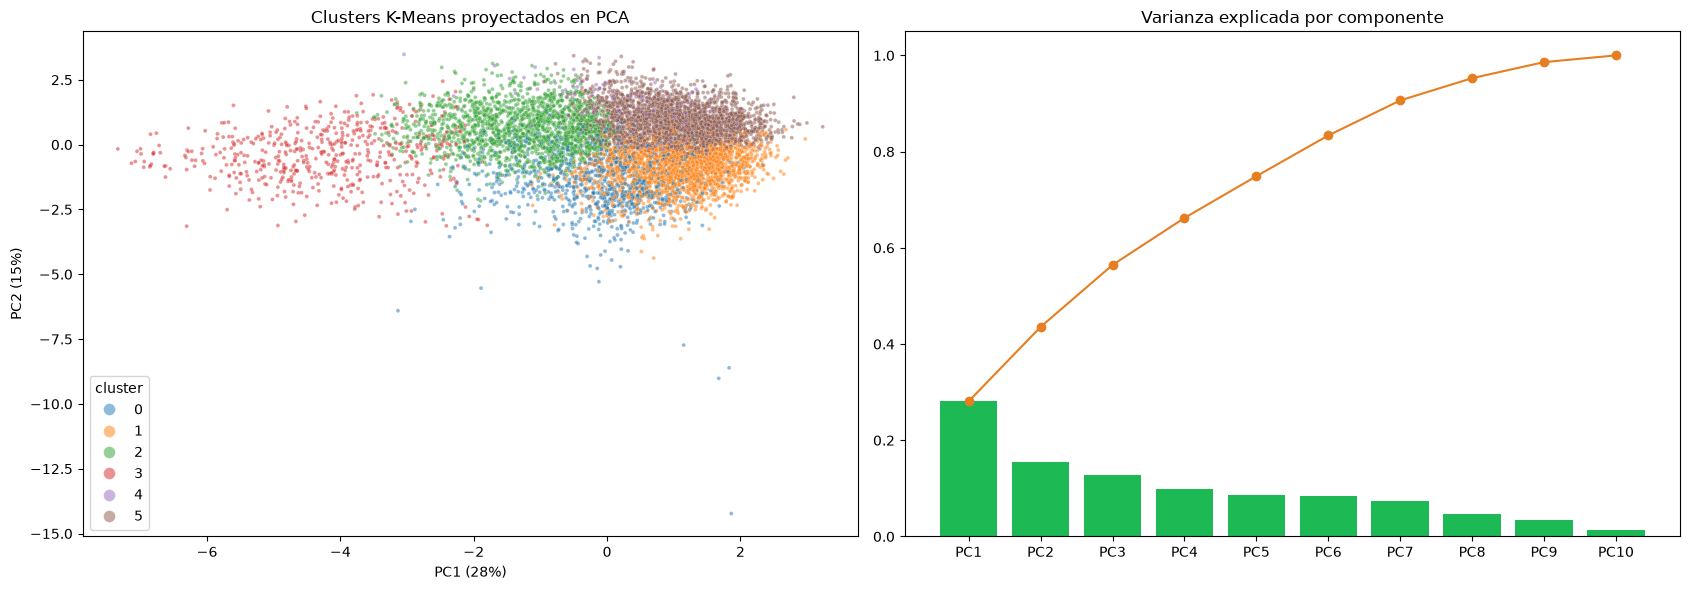

                    INFO     Loading data from pca_loadings (CSVDataset)...                    ]8;id=12544711;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=12544712;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,feature,PC1,PC2
0,danceability,0.223,0.494
1,energy,0.516,-0.251
2,loudness,0.523,-0.066
3,speechiness,0.091,0.145
4,acousticness,-0.438,0.325
5,instrumentalness,-0.283,-0.332
6,liveness,0.097,-0.088
7,valence,0.285,0.503
8,tempo,0.198,-0.234
9,duration_min,-0.000,-0.369


In [5]:
display(Image(f"{PLOTS}/05_pca_clusters.png"))
catalog.load("pca_loadings")

- **PC1 (28%)** = *intensidad*: alta energía y volumen vs. acústica (loadings energy 0.52, loudness 0.52, acousticness −0.44).
- **PC2 (15%)** = *ánimo bailable*: danceability (0.49) y valence (0.50) vs. instrumental y canciones largas.
- Con 2 componentes se explica el 44% de la varianza; los clusters se ven ordenados a lo largo de estos ejes con zonas de solapamiento, coherente con el silhouette moderado.

## 3. Perfil de los segmentos

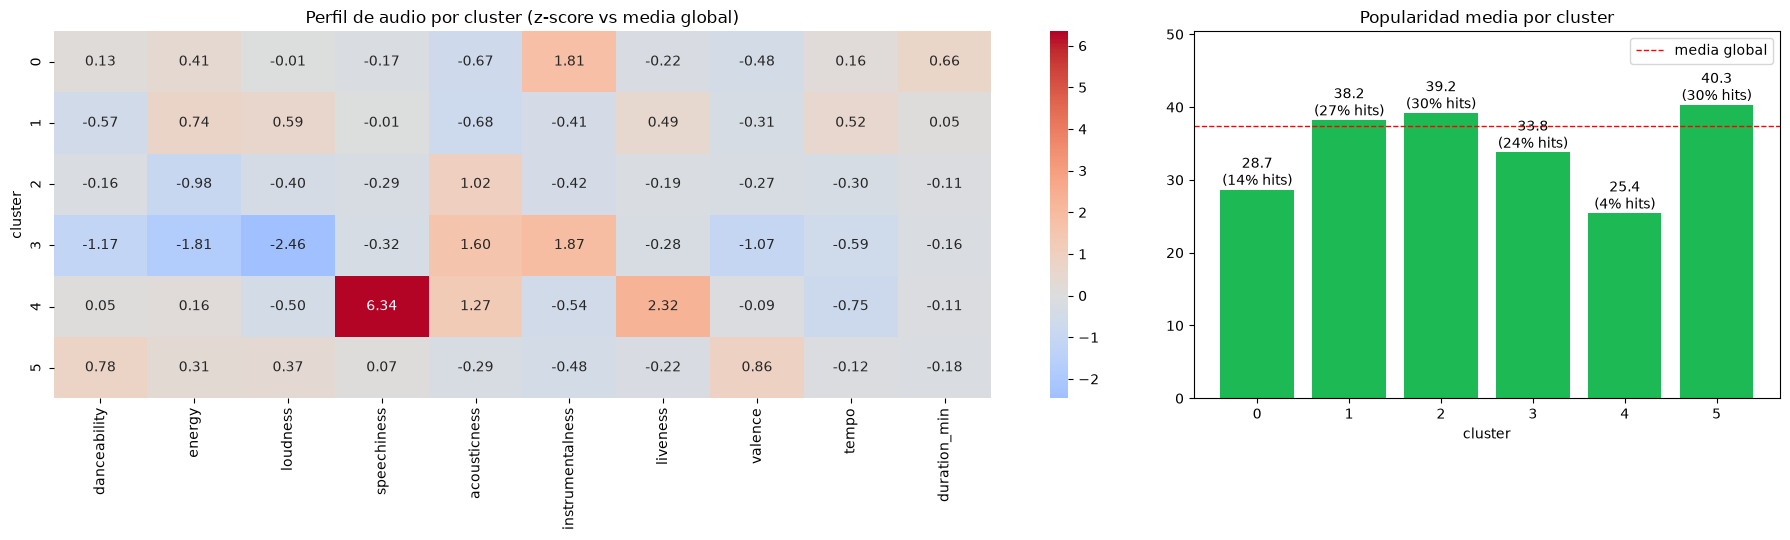

In [6]:
display(Image(f"{PLOTS}/05_cluster_profiles.png"))

In [7]:
NOMBRES = {
    0: "Electrónica instrumental",
    1: "Intensa / rock-metal",
    2: "Acústica melódica",
    3: "Ambiental / relajación",
    4: "Hablada / en vivo",
    5: "Bailable y alegre",
}

perfil = catalog.load("cluster_profiles")
perfil.insert(1, "segmento", perfil["cluster"].map(NOMBRES))
perfil[["cluster", "segmento", "n_canciones", "pct_canciones", "popularity_media", "tasa_hit", "explicit", "top_5_generos"]]

                    INFO     Loading data from cluster_profiles (CSVDataset)...                ]8;id=12544717;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=12544718;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,cluster,segmento,n_canciones,pct_canciones,popularity_media,tasa_hit,explicit,top_5_generos
0,0,Electrónica instrumental,9310,0.122,28.670,0.141,0.033,"detroit-techno, minimal-techno, chicago-house, idm, trance"
1,1,Intensa / rock-metal,19754,0.258,38.217,0.269,0.099,"heavy-metal, metalcore, hardstyle, death-metal, grunge"
2,2,Acústica melódica,16377,0.214,39.181,0.299,0.043,"tango, honky-tonk, cantopop, mandopop, show-tunes"
3,3,Ambiental / relajación,5529,0.072,33.766,0.242,0.003,"new-age, sleep, ambient, piano, guitar"
4,4,Hablada / en vivo,1032,0.014,25.411,0.038,0.565,"comedy, show-tunes, kids, children, french"
5,5,Bailable y alegre,24437,0.320,40.320,0.303,0.126,"kids, salsa, forro, j-dance, dancehall"


| # | Segmento | Perfil de audio | Popularidad | % hits |
|---|---|---|---|---|
| 5 | **Bailable y alegre** (32%) | Alta danceability (0.70) y valence (0.69) — salsa, forró, dancehall | **40.3** | **30%** |
| 2 | **Acústica melódica** (21%) | Acústica, baja energía, con voz — tango, honky-tonk, cantopop | 39.2 | 30% |
| 1 | **Intensa / rock-metal** (26%) | Máxima energía y volumen, tempo rápido — metal, hardstyle | 38.2 | 27% |
| 3 | **Ambiental / relajación** (7%) | Muy silenciosa, acústica e instrumental — new-age, sleep, piano | 33.8 | 24% |
| 0 | **Electrónica instrumental** (12%) | Energética pero instrumental (0.78) y larga (5.1 min) — techno, house, IDM | 28.7 | 14% |
| 4 | **Hablada / en vivo** (1%) | Speechiness 0.84, liveness 0.68 — comedia, musicales, infantil | 25.4 | 4% |

La popularidad **no se usó** para formar los clusters, pero difiere claramente entre ellos: el sonido sí agrupa canciones con distinto potencial comercial.

## 4. Segmentos vs géneros

Géneros con >80% de sus canciones en un solo segmento: 14 de 114
Géneros repartidos (ningún segmento >50%): 40


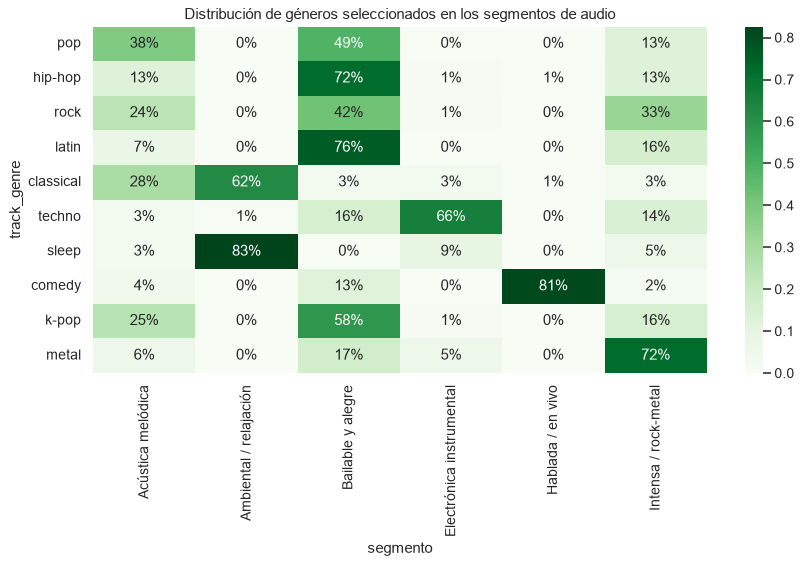

In [8]:
NOMBRES = {
    0: "Electrónica instrumental",
    1: "Intensa / rock-metal",
    2: "Acústica melódica",
    3: "Ambiental / relajación",
    4: "Hablada / en vivo",
    5: "Bailable y alegre",
}

df = features.copy()
df["segmento"] = labels["cluster"].map(NOMBRES).values
pureza = df.groupby("track_genre")["segmento"].agg(lambda s: s.value_counts(normalize=True).iloc[0])
print(f"Géneros con >80% de sus canciones en un solo segmento: {(pureza > 0.8).sum()} de {len(pureza)}")
print(f"Géneros repartidos (ningún segmento >50%): {(pureza < 0.5).sum()}")

top_gen = df["track_genre"].value_counts().index
ejemplo = ["pop", "hip-hop", "rock", "latin", "classical", "techno", "sleep", "comedy", "k-pop", "metal"]
tabla = pd.crosstab(df["track_genre"], df["segmento"], normalize="index").loc[ejemplo]
plt.figure(figsize=(11, 5))
sns.heatmap(tabla, annot=True, fmt=".0%", cmap="Greens")
plt.title("Distribución de géneros seleccionados en los segmentos de audio")
plt.show()

Algunos géneros caen casi completos en un segmento (sleep → Ambiental, comedy → Hablada), pero géneros como **pop (49% / 38% / 13%) o rock (42% / 33% / 24%) se reparten entre varios**: el clustering descubre una segmentación **por sonido** que complementa la etiqueta de género.

## 5. Contraste con DBSCAN

In [9]:
catalog.load("dbscan_results")

                    INFO     Loading data from dbscan_results (CSVDataset)...                  ]8;id=12544723;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=12544724;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,modelo,eps,n_clusters,pct_ruido,pct_cluster_mayor,silhouette
0,DBSCAN,0.5,4,0.5511,0.4383,0.0370
1,DBSCAN,0.8,1,0.1238,0.8762,NaN
2,DBSCAN,1.2,2,0.0225,0.9699,0.5935
3,KMeans,NaN,6,0.0000,0.3173,0.2286


DBSCAN (sobre 5 componentes PCA, muestra de 15.000 canciones) no encuentra una estructura útil:

- `eps=0.5`: 55% de las canciones quedan como **ruido**.
- `eps=0.8`: todo cae en **1 solo cluster**.
- `eps=1.2`: el 97% en un cluster gigante (su silhouette alto es engañoso: solo separa un pequeño grupo de outliers).

Esto confirma que las canciones forman un **continuo denso sin grupos naturales separados**. En ese escenario, K-Means es más adecuado porque *particiona* el espacio en segmentos balanceados e interpretables, que es lo que necesita el negocio.

## 6. Recomendaciones de negocio

1. **Priorizar la promoción en "Bailable y alegre" y "Acústica melódica"**: son el 53% del catálogo y tienen la mayor tasa de hits (30%).
2. **"Electrónica instrumental" tiene la mitad de tasa de hits (14%)**: orientarla a playlists de nicho (concentración, clubes) en vez de campañas masivas.
3. **"Ambiental / relajación"** tiene popularidad media aceptable (33.8) con un perfil muy definido: ideal para playlists funcionales (dormir, estudiar).
4. **"Hablada / en vivo"** casi no genera hits (4%): no es contenido musical de consumo masivo; separarlo del catálogo musical en las recomendaciones.
5. Usar el **segmento como feature de recomendación**: canciones de distinto género pero mismo segmento de sonido son buenos candidatos para "si te gustó X, escucha Y".

---
# Conclusiones generales del proyecto

| Modelo | Tarea | Mejor algoritmo | Resultado |
|---|---|---|---|
| Clasificación | ¿Será hit? (`popularity >= 50`) | Gradient Boosting | F1 = 0.68, ROC-AUC = 0.88; promocionando el top 10%, **85% son hits** (3.2x vs azar) |
| Regresión | Popularidad 1–100 | Gradient Boosting | MAE = 8.65 puntos (−42% vs baseline), R² = 0.53 |
| No supervisado | Segmentación por sonido | K-Means (k=6) | 6 segmentos interpretables con tasas de hit entre 4% y 30% |

**Hallazgos clave:**

1. El **género** es, por lejos, el principal determinante de la popularidad; las características de audio aportan una señal menor pero consistente.
2. Las canciones **bailables, alegres, explícitas y colaborativas** tienden a ser más populares; las **instrumentales, habladas, en vivo y largas**, menos.
3. Los modelos de árboles con boosting superan a los lineales, pero la diferencia es moderada: gran parte de la señal es aditiva.

**Limitaciones y consideraciones éticas:**

- El dataset tiene 1.000 canciones por género (muestreo artificial), no representa el catálogo real de Spotify.
- Faltan variables decisivas: popularidad del artista, inversión en marketing, fecha de lanzamiento.
- **Riesgo de homogeneización:** usar estos modelos para decidir qué promocionar refuerza a los géneros ya populares y reduce la visibilidad de géneros de nicho, regionales o de artistas emergentes (ej. tango, música iraní, IDM). Se recomienda usarlos como apoyo y reservar cuotas de promoción para diversidad musical.